# Thí nghiệm cấu hình A — MLP với lịch sử và mô tả thời tiết

So **A + lịch sử** với **A + lịch sử + weather_description**, giữ bộ tham số MLP, nguồn dữ liệu và cách chia fold của V1. Notebook đọc `data/processed/train.csv` và `validation.csv`, rồi dùng nhóm cột nhị phân `weather_description_*` đã mã hóa trong hai file.

Cả hai phương án dùng `lag_24h`, `lag_168h` và `mean_24h` từ lưu lượng thực tế đã quan sát. V3 giả định mô tả thời tiết của giờ cần dự đoán có sẵn. Đối chiếu hai phương án trên cùng các giờ đủ lịch sử.

## Params

In [1]:
MODEL_PARAMS = {
    "MLP": {
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "alpha": 0.001,
        "learning_rate_init": 0.001,
        "batch_size": 256,
        "max_iter": 500,
        "early_stopping": False,
        "random_state": 42,
    },
}

CV_SPLITS = 3
CALENDAR_COLUMNS = ["hour", "day_of_week", "month"]
BINARY_COLUMNS = ["is_weekend", "is_holiday"]
TARGET_COLUMN = "traffic_volume"
CLIP_NEGATIVE_PREDICTIONS = True
HOURS_TO_PLOT = 72

## Đọc dữ liệu, tạo lịch sử và chọn cột mô tả thời tiết

In [2]:
from datetime import datetime
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cwd = Path.cwd()
project_dir = next(
    (
        candidate
        for parent in (cwd, *cwd.parents)
        for candidate in (parent, parent / "metro_interstate_traffic_volume")
        if (candidate / "data" / "processed" / "train.csv").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy data/processed/train.csv.")

if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

from src.features import HISTORY_FEATURES, add_history_features

processed_dir = project_dir / "data" / "processed"
train = pd.read_csv(processed_dir / "train.csv", parse_dates=["date_time"])
validation = pd.read_csv(processed_dir / "validation.csv", parse_dates=["date_time"])

assert train.columns.equals(validation.columns)
for part in (train, validation):
    assert part["date_time"].is_unique
    assert part["date_time"].is_monotonic_increasing
assert train["date_time"].max() < validation["date_time"].min()

holiday_columns = [column for column in train.columns if column.startswith("holiday_")]
binary_columns = BINARY_COLUMNS + holiday_columns
features_A = CALENDAR_COLUMNS + binary_columns

history_table = add_history_features(
    pd.concat([train, validation], ignore_index=True)
)
train = history_table.iloc[:len(train)].copy()
validation = history_table.iloc[len(train):].copy()

weather_description_columns = [
    column for column in train.columns if column.startswith("weather_description_")
]
if not weather_description_columns:
    raise ValueError("Không tìm thấy các cột weather_description_* trong data/processed.")

features_with_history = [*features_A, *HISTORY_FEATURES]
CONFIG_FEATURES = {
    "A + lịch sử": features_with_history,
    "A + lịch sử + mô tả thời tiết": [*features_with_history, *weather_description_columns],
}
print(f"Số cột mô tả thời tiết: {len(weather_description_columns)}")

display(pd.DataFrame([
    {
        "Tập": name,
        "Tổng số giờ": len(part),
        "Số giờ đủ lịch sử": part[HISTORY_FEATURES].notna().all(axis=1).sum(),
    }
    for name, part in (("Train", train), ("Validation", validation))
]))

Số cột mô tả thời tiết: 38


,Tập,Tổng số giờ,Số giờ đủ lịch sử
0,Train,28402,22503
1,Validation,6086,6050


## So sánh trên 3 fold theo thời gian

Tạo ranh giới các fold trên train theo cách V2 dùng. Sau đó giữ những giờ đủ lịch sử trong phần học và phần chấm của mỗi fold, dùng cùng các dòng cho hai mô hình. Tổng cộng có 6 lần fit trong CV.

In [3]:
def fit_mlp(frame, config):
    columns = CONFIG_FEATURES[config]
    transformers = [
        ("calendar", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CALENDAR_COLUMNS),
        ("binary", "passthrough", binary_columns),
    ]
    transformers.append(("history", StandardScaler(), HISTORY_FEATURES))
    if config == "A + lịch sử + mô tả thời tiết":
        transformers.append(("weather_description", "passthrough", weather_description_columns))

    pipeline = Pipeline([
        ("preprocessing", ColumnTransformer(transformers)),
        ("model", TransformedTargetRegressor(
            regressor=MLPRegressor(**MODEL_PARAMS["MLP"]),
            transformer=StandardScaler(),
        )),
    ])
    return pipeline.fit(frame[columns], frame[TARGET_COLUMN])


def predict_volume(model, frame, config):
    prediction = model.predict(frame[CONFIG_FEATURES[config]])
    if CLIP_NEGATIVE_PREDICTIONS:
        prediction = prediction.clip(min=0)
    return prediction


def keep_history(frame):
    return frame.dropna(subset=HISTORY_FEATURES)


cv_rows = []
for fold, (train_idx, score_idx) in enumerate(TimeSeriesSplit(n_splits=CV_SPLITS).split(train), start=1):
    fit = keep_history(train.iloc[train_idx])
    score = keep_history(train.iloc[score_idx])
    for config in CONFIG_FEATURES:
        print(f"Fold {fold}/{CV_SPLITS} · {config}", flush=True)
        model = fit_mlp(fit, config)
        prediction = predict_volume(model, score, config)
        cv_rows.append({
            "Cấu hình": config,
            "Fold": fold,
            "Giờ train": len(fit),
            "Giờ chấm": len(score),
            "Train đến": fit["date_time"].max(),
            "Chấm từ": score["date_time"].min(),
            "Chấm đến": score["date_time"].max(),
            "MAE": mean_absolute_error(score[TARGET_COLUMN], prediction),
        })

cv_table = pd.DataFrame(cv_rows)
cv_summary = cv_table.groupby("Cấu hình", sort=False)["MAE"].mean().rename("MAE CV").reset_index()
display(cv_table.round(3))
display(cv_summary.round(3))

Fold 1/3 · A + lịch sử
Fold 1/3 · A + lịch sử + mô tả thời tiết
Fold 2/3 · A + lịch sử
Fold 2/3 · A + lịch sử + mô tả thời tiết
Fold 3/3 · A + lịch sử
Fold 3/3 · A + lịch sử + mô tả thời tiết


,Cấu hình,Fold,Giờ train,Giờ chấm,Train đến,Chấm từ,Chấm đến,MAE
0,A + lịch sử,1,5841,5302,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,247.266
1,A + lịch sử + mô tả thời tiết,1,5841,5302,2013-08-18 18:00:00,2013-08-18 19:00:00,2015-07-07 11:00:00,282.794
2,A + lịch sử,2,11143,4441,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,245.850
3,A + lịch sử + mô tả thời tiết,2,11143,4441,2015-07-07 11:00:00,2015-07-07 12:00:00,2016-07-15 04:00:00,253.758
4,A + lịch sử,3,15584,6919,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,254.676
5,A + lịch sử + mô tả thời tiết,3,15584,6919,2016-07-15 04:00:00,2016-07-15 05:00:00,2017-05-10 04:00:00,270.009


,Cấu hình,MAE CV
0,A + lịch sử,249.264
1,A + lịch sử + mô tả thời tiết,268.854


## Đánh giá trên validation và lưu Excel

Fit lại cả hai mô hình trên cùng tập train đủ lịch sử. Chấm cả hai trên cùng các giờ validation đủ lịch sử. Mỗi lần chạy tạo một file Excel, ghi tham số, MAE, RMSE, R² và điểm từng fold.

In [4]:
fit = keep_history(train)
score = keep_history(validation)
prediction_table = score[["date_time", TARGET_COLUMN]].copy()
rows = []
for config in CONFIG_FEATURES:
    print(f"Validation · {config}", flush=True)
    model = fit_mlp(fit, config)
    prediction = predict_volume(model, score, config)
    prediction_table[config] = prediction
    rows.append({
        "Cấu hình": config,
        "Số đặc trưng": len(CONFIG_FEATURES[config]),
        "Giờ train": len(fit),
        "Giờ validation": len(score),
        "MAE": mean_absolute_error(score[TARGET_COLUMN], prediction),
        "RMSE": mean_squared_error(score[TARGET_COLUMN], prediction) ** 0.5,
        "R2": r2_score(score[TARGET_COLUMN], prediction),
        "n_iter": model.named_steps["model"].regressor_.n_iter_,
    })

params = {**MODEL_PARAMS["MLP"], "hidden_layer_sizes": str(MODEL_PARAMS["MLP"]["hidden_layer_sizes"])}
results = pd.DataFrame(rows).merge(cv_summary, on="Cấu hình", validate="one_to_one").assign(**params)
baseline_mae = results.loc[results["Cấu hình"].eq("A + lịch sử"), "MAE"].iloc[0]
results["Chênh MAE so với A + lịch sử"] = results["MAE"] - baseline_mae
display(results.round({"MAE": 3, "RMSE": 3, "R2": 4, "MAE CV": 3}))

run_id = datetime.now().astimezone().strftime("%Y%m%d_%H%M%S_%f")
experiment_dir = project_dir / "experiments" / "18-11-2026_ConfigA_HistoryMLP_Phuc"
excel_path = experiment_dir / f"ConfigA_MLP_History_V3_WeatherDescription_{run_id}.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Kết quả", index=False)
    cv_table.to_excel(writer, sheet_name="CV từng fold", index=False)
print(f"Đã lưu Excel tại {excel_path}")

Validation · A + lịch sử
Validation · A + lịch sử + mô tả thời tiết


,Cấu hình,Số đặc trưng,Giờ train,Giờ validation,MAE,RMSE,R2,n_iter,MAE CV,hidden_layer_sizes,activation,solver,alpha,learning_rate_init,batch_size,max_iter,early_stopping,random_state,Chênh MAE so với A + lịch sử
0,A + lịch sử,20,22503,6050,194.780,302.769,0.9762,57,249.264,"(64, 32)",relu,adam,0.001,0.001,256,500,False,42,0.000000
1,A + lịch sử + mô tả thời tiết,58,22503,6050,214.413,322.783,0.9730,73,268.854,"(64, 32)",relu,adam,0.001,0.001,256,500,False,42,19.632993


Đã lưu Excel tại d:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\18-11-2026_ConfigA_HistoryMLP_Phuc\ConfigA_MLP_History_V3_WeatherDescription_20261118_095954_877515.xlsx


## Vẽ và lưu biểu đồ dự đoán

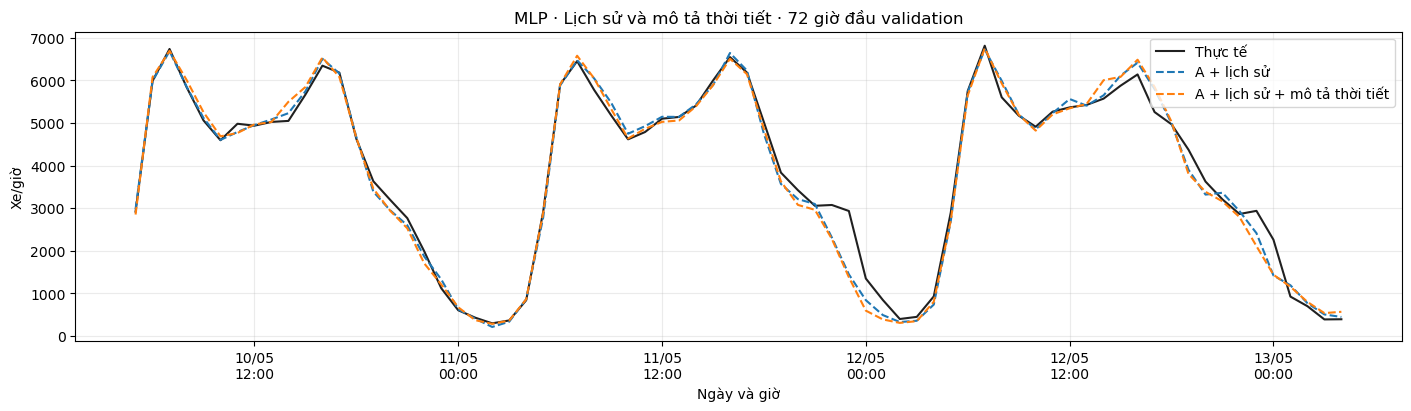

In [5]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

plot_index = pd.date_range(
    start=prediction_table["date_time"].min(),
    periods=HOURS_TO_PLOT,
    freq="h",
)
# Giữ NaN ở các giờ thiếu để biểu đồ ngắt tại khoảng trống.
plot_data = prediction_table.set_index("date_time").reindex(plot_index)

fig, ax = plt.subplots(figsize=(14, 4), layout="constrained")
ax.plot(plot_data.index, plot_data[TARGET_COLUMN], color="#202020", label="Thực tế")
for config in CONFIG_FEATURES:
    ax.plot(plot_data.index, plot_data[config], linestyle="--", label=config)
ax.set_title("MLP · Lịch sử và mô tả thời tiết · 72 giờ đầu validation")
ax.set_ylabel("Xe/giờ")
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
ax.set_xlabel("Ngày và giờ")

output_dir = experiment_dir / "img"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"config_a_mlp_history_v3_weather_description_{HOURS_TO_PLOT}h_{run_id}.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

## Nhận xét sau khi chạy

Lần chạy `20261118_095954_877515` so sánh hai phương án với cùng bộ tham số MLP, **22.503 giờ train** và **6.050 giờ validation** đủ lịch sử. V3 bổ sung 38 cột `weather_description_*`.

| Chỉ số (xe/giờ) | A + lịch sử | A + lịch sử + mô tả thời tiết | Mức tăng |
|---|---:|---:|---:|
| MAE fold 1 | 247,27 | 282,79 | +35,53 |
| MAE fold 2 | 245,85 | 253,76 | +7,91 |
| MAE fold 3 | 254,68 | 270,01 | +15,33 |
| MAE CV trung bình | 249,26 | 268,85 | +19,59 |
| MAE validation | 194,78 | 214,41 | +19,63 |
| RMSE validation | 302,77 | 322,78 | +20,01 |

MAE tăng ở cả ba fold và tăng **10,08%** trên validation. R² validation giảm từ **0,9762** xuống **0,9730**. Với bộ tham số MLP và cách mã hóa đang dùng, thêm mô tả thời tiết làm sai số tăng. Trong các lượt ngày 18/11, **V1 · A + lịch sử** có MAE validation thấp nhất.